# Day 19 — ARIMA Forecasting: Static vs Walk-Forward

We forecast the last 44 months of AirPassengers with the same ARIMA(12,1,2) model in two ways:
1. **Static:** fit once on the training data, then forecast all 44 months in one go.
2. **Walk-forward:** forecast one month ahead, add that month's real value to the history, refit, and repeat. This mirrors real use: each month you learn the actual number before predicting the next one.

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning

# 15 parameters on ~100 points: the optimizer often stops just short of convergence and resets its starting values; harmless here, but noisy over 44 refits
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", EstimationWarning)

## 1. Load the data

In [2]:
df = pd.read_csv("../../data/AirPassengers.csv", parse_dates=["Month"], index_col="Month")
df.index.freq = "MS"  # monthly data, stamped at month start
ts = df["#Passengers"]

print(ts.shape)
ts.head()

(144,)


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: #Passengers, dtype: int64

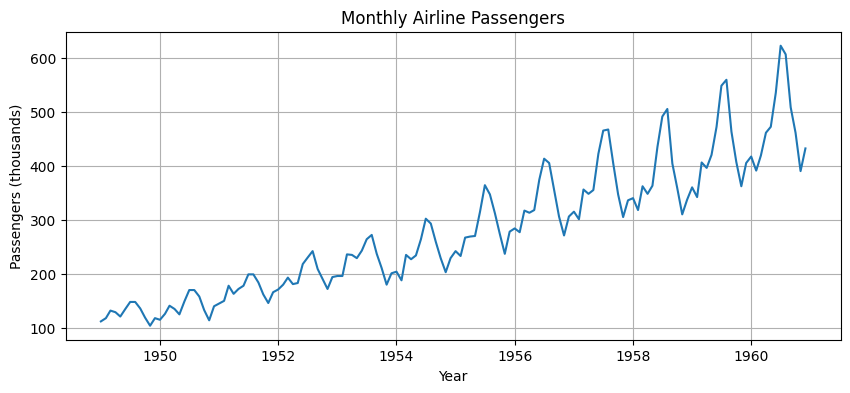

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(ts)
plt.title("Monthly Airline Passengers")
plt.xlabel("Year")
plt.ylabel("Passengers (thousands)")
plt.grid(True)
plt.show()

## 2. Chronological train-test split

A time series can't be shuffled: we train on the first 70% of months and test on the last 30%.

In [4]:
size = int(len(ts) * 0.7)

train = ts.iloc[:size]
test = ts.iloc[size:]

print("Training observations:", len(train), f"({train.index[0]:%Y-%m} to {train.index[-1]:%Y-%m})")
print("Testing observations: ", len(test), f"({test.index[0]:%Y-%m} to {test.index[-1]:%Y-%m})")

Training observations: 100 (1949-01 to 1957-04)
Testing observations:  44 (1957-05 to 1960-12)


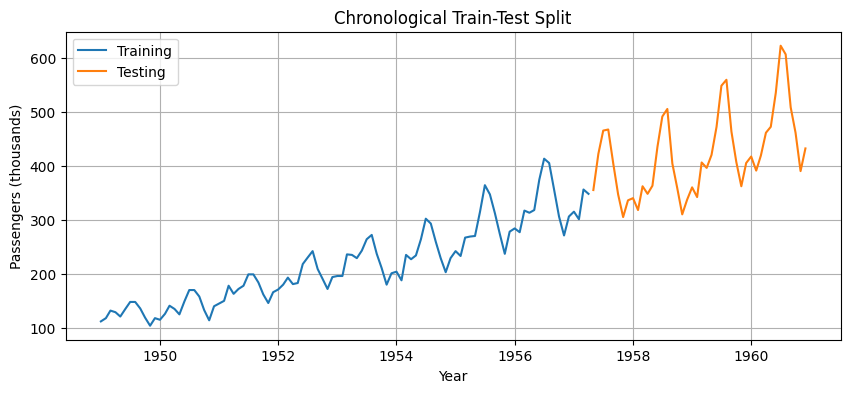

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(train, label="Training")
plt.plot(test, label="Testing")
plt.title("Chronological Train-Test Split")
plt.xlabel("Year")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True)
plt.show()

## 3. Static forecast (baseline)

ARIMA(12,1,2) on the **log** series:
- **log** stabilizes the seasonal swings that grow over time (Day 18),
- **d = 1** removes the trend,
- **p = 12** lets the model look back a full year, so it can pick up the yearly seasonality,
- **q = 2** corrects using the last two forecast errors.

In [6]:
log_ts = np.log(ts)
log_train = log_ts.iloc[:size]

model_fit = ARIMA(log_train, order=(12, 1, 2)).fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            #Passengers   No. Observations:                  100
Model:                ARIMA(12, 1, 2)   Log Likelihood                 161.979
Date:                Mon, 09 Nov 2026   AIC                           -293.958
Time:                        17:12:45   BIC                           -255.031
Sample:                    01-01-1949   HQIC                          -278.208
                         - 04-01-1957                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1113      0.115      0.965      0.334      -0.115       0.337
ar.L2         -0.0759      0.096     -0.786      0.432      -0.265       0.113
ar.L3          0.0187      0.062      0.300      0.7

In [7]:
static_forecast = np.exp(model_fit.forecast(steps=len(test)))  # back from log to passengers

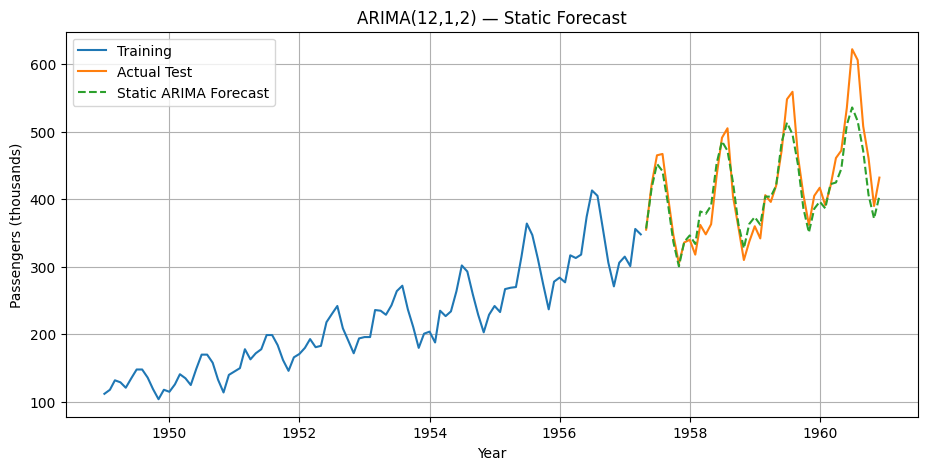

In [8]:
plt.figure(figsize=(11, 5))
plt.plot(train, label="Training")
plt.plot(test, label="Actual Test")
plt.plot(static_forecast, label="Static ARIMA Forecast", linestyle="--")
plt.title("ARIMA(12,1,2) — Static Forecast")
plt.xlabel("Year")
plt.ylabel("Passengers (thousands)")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
def evaluate(actual, forecast):
    err = actual.values - forecast.values
    return {
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "MAE": np.mean(np.abs(err)),
        "MAPE (%)": np.mean(np.abs(err) / actual.values) * 100,
    }

for metric, value in evaluate(test, static_forecast).items():
    print(f"Static {metric}: {value:.2f}")

Static RMSE: 29.22
Static MAE: 21.47
Static MAPE (%): 4.76


## 4. Walk-forward forecast

For each test month `t`:
1. take every month known so far (`log_ts.iloc[:size + t]`),
2. refit ARIMA(12,1,2) on it,
3. forecast **one** month ahead,
4. step forward, so the real value for month `t` becomes part of the history.

In [10]:
wf_log_preds = []

for t in range(len(test)):
    history = log_ts.iloc[:size + t]
    fit = ARIMA(history, order=(12, 1, 2)).fit()
    wf_log_preds.append(fit.forecast(steps=1).iloc[0])

wf_forecast = np.exp(pd.Series(wf_log_preds, index=test.index))
wf_forecast.head()

Month
1957-05-01    356.608322
1957-06-01    415.128584
1957-07-01    455.906356
1957-08-01    450.242392
1957-09-01    411.469372
Freq: MS, dtype: float64

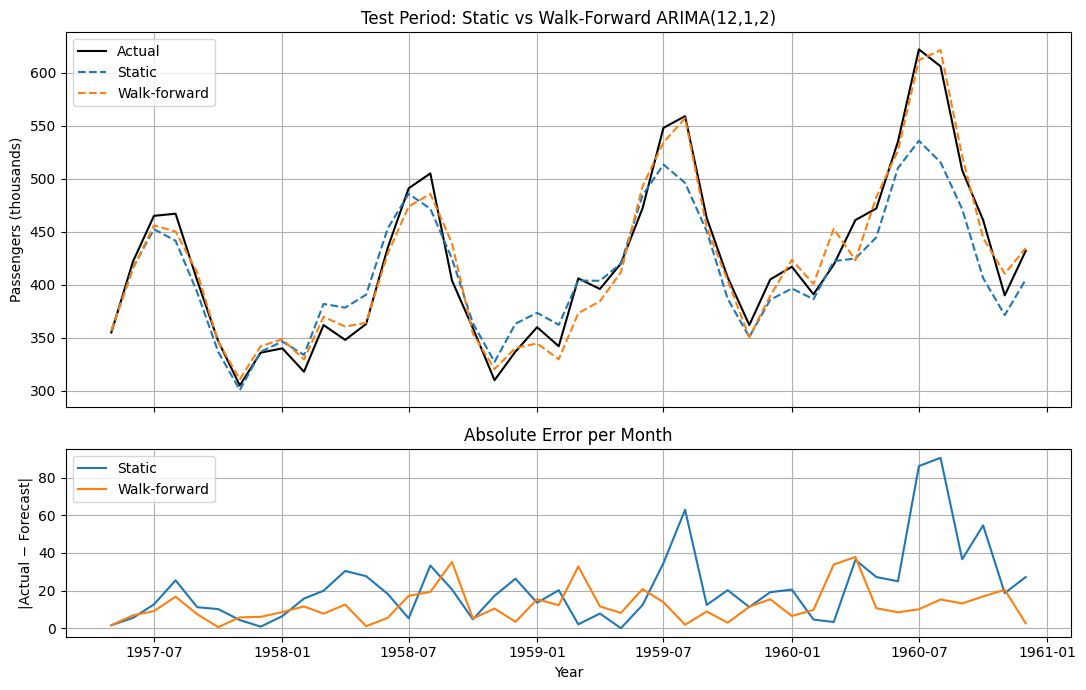

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

axes[0].plot(test, label="Actual", color="black")
axes[0].plot(static_forecast, label="Static", linestyle="--")
axes[0].plot(wf_forecast, label="Walk-forward", linestyle="--")
axes[0].set_title("Test Period: Static vs Walk-Forward ARIMA(12,1,2)")
axes[0].set_ylabel("Passengers (thousands)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot((test - static_forecast).abs(), label="Static")
axes[1].plot((test - wf_forecast).abs(), label="Walk-forward")
axes[1].set_title("Absolute Error per Month")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("|Actual − Forecast|")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 5. Comparison

A **naive** forecast (next month = this month) is added as a reference, because a model that can't beat it isn't useful.

In [12]:
naive_forecast = ts.shift(1).loc[test.index]

results = pd.DataFrame({
    "Static ARIMA": evaluate(test, static_forecast),
    "Walk-forward ARIMA": evaluate(test, wf_forecast),
    "Naive (last month)": evaluate(test, naive_forecast),
}).T.round(2)

results

,RMSE,MAE,MAPE (%)
Static ARIMA,29.22,21.47,4.76
Walk-forward ARIMA,15.02,12.12,2.88
Naive (last month),49.41,41.73,9.92


In [13]:
# Mean % error per test year (1957 covers May-Dec only): does the error grow the further we forecast?
pct_error = pd.DataFrame({
    "Static": (test - static_forecast).abs() / test * 100,
    "Walk-forward": (test - wf_forecast).abs() / test * 100,
})
pct_error.groupby(test.index.year).mean().round(1)

,Static,Walk-forward
Month,,
1957,2.2,1.7
1958,5.0,2.9
1959,4.0,3.1
1960,7.0,3.4


## 6. Results

- **Walk-forward halves the error:** RMSE 29.2 → 15.0 and MAPE 4.8% → 2.9%.
- **The static forecast drifts the further it goes.** Its error climbs from 2.2% in 1957 to 7.0% in 1960, and it misses the summer peaks badly (July 1960: 536 forecast vs 622 actual). It never sees data after April 1957, while the peaks keep growing.
- **Walk-forward stays close** (1.7–3.4% per year). Every forecast is only one month ahead and starts from the latest real values, so errors don't build up.
- **Both beat the naive forecast** (RMSE 49.4), so the model really learns the trend and seasonality rather than just copying last month.
- **Caveat:** the two methods answer different questions. Walk-forward asks "what's next month?" and static asks "what are the next 44 months?". Walk-forward is the right test when the model is updated with new data each month; static is closer to long-range planning, where there is no new data to lean on.